In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducible lectures
np.random.seed(42)

## Part 1: Generating the population

In [31]:
# We use a Gamma distribution because it naturally models wait times: 
# strictly positive, with a heavy right tail (the "broken espresso machine" effect).

n_pop_per_group = 50000

# TRUE POPULATION PARAMS: Mobile = ~4.2 mins, Walk-in = ~6.1 mins
# Gamma mean = shape * scale
mobile_pop = np.random.gamma(shape=2.0, scale=2.1, size=n_pop_per_group)
walkin_pop = np.random.gamma(shape=2.5, scale=2.44, size=n_pop_per_group)

# Build the population Database
df_pop = pd.DataFrame({
    'order_type': ['Mobile'] * n_pop_per_group + ['Walk-in'] * n_pop_per_group,
    'wait_time': np.concatenate([mobile_pop, walkin_pop])
})

true_pop_diff = df_pop[df_pop['order_type'] == 'Walk-in']['wait_time'].mean() - \
                df_pop[df_pop['order_type'] == 'Mobile']['wait_time'].mean()

# print(f"True Population Difference: {true_pop_diff:.2f} minutes\n")

In [3]:
df_pop.head()

,order_type,wait_time
0,Mobile,5.026727
1,Mobile,3.138376
2,Mobile,2.902796
3,Mobile,2.902835
4,Mobile,9.764400


In [4]:
# get population statistics
df_pop.wait_time.describe()

count    100000.000000
mean          5.152432
std           3.565683
min           0.011599
25%           2.527993
50%           4.361262
75%           6.927161
max          39.294821
Name: wait_time, dtype: float64

## Part 2: Taking a sample from the population

In [5]:
# Let's observe a sample of 30 from each group and see what we get. This is the data we actually have in the real world.
sample_size = 30 

# Take a random sample without replacement from each group
df_sample_mobile = df_pop[df_pop['order_type'] == 'Mobile'].sample(sample_size)
df_sample_walkin = df_pop[df_pop['order_type'] == 'Walk-in'].sample(sample_size)
df_sample = pd.concat([df_sample_mobile, df_sample_walkin])

In [6]:
df_sample.head()

,order_type,wait_time
10632,Mobile,1.901416
47403,Mobile,1.253712
4484,Mobile,11.189804
22707,Mobile,5.707341
24181,Mobile,2.171481


In [7]:
df_sample.describe()

,wait_time
count,60.000000
mean,4.835961
std,3.273438
min,0.204252
25%,1.950132
50%,4.222507
75%,6.654916
max,12.506447


## Part 3: Sampling Variance

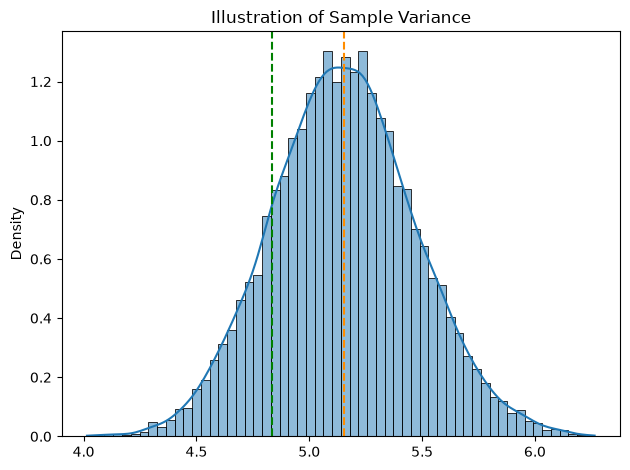

In [18]:
# Create 1,000 samples of size 60 and plot the distribution of their means
n_samples = 10000
n_per_sample = 60

means = np.empty(n_samples)
walkin_means = np.empty(n_samples)
mobile_means = np.empty(n_samples)

for i in range(n_samples):
    sim_w = np.random.choice(np.array(walkin_pop), size=n_per_sample, replace=False)
    sim_m = np.random.choice(np.array(mobile_pop), size=n_per_sample, replace=False)

    means[i] = np.mean(np.concatenate([sim_w, sim_m]))
    walkin_means[i] = np.mean(sim_w)
    mobile_means[i] = np.mean(sim_m)

sns.histplot(means, kde=True, label='Combined Means', stat='density')

# plot vertical line at the sample mean
plt.axvline(x=df_sample['wait_time'].mean(), color='green', linestyle='--', label='Sample Mean')

# plot vertical line at the population mean
plt.axvline(x=df_pop['wait_time'].mean(), color='darkorange', linestyle='--', label='True Population Difference')

plt.title('Illustration of Sample Variance')

plt.tight_layout()
plt.show()

## Part 4: Hypothesis Test

In [21]:
print(f'Mobile wait time: {df_sample_mobile["wait_time"].mean()}')
print(f'Walk-in wait time: {df_sample_walkin["wait_time"].mean()}')

Mobile wait time: 3.8691587034824177
Walk-in wait time: 5.802762842337106


Observed difference: 1.93
--- Permutation Test ---
P-value: 0.0114
Conclusion: Only 1.14% of random universes produced a gap this big.



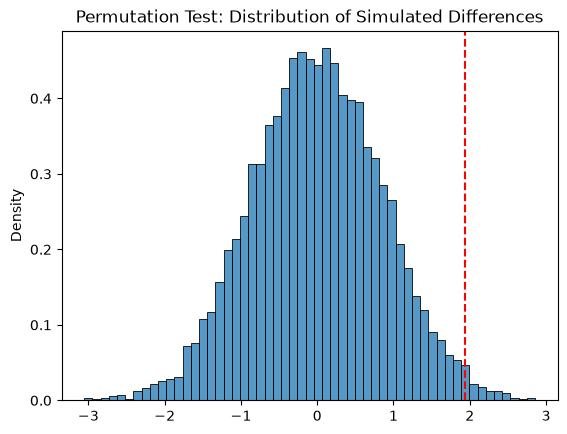

In [28]:

# ==============================================================================
# PART 3: Permutation Test (How likely is our observed difference under the null?)
# ==============================================================================
n_iter = 10000
perm_diffs = np.zeros(n_iter)

obs_diff = df_sample_walkin['wait_time'].mean() - df_sample_mobile['wait_time'].mean()
print(f"Observed difference: {obs_diff:.2f}")

# Extract to NumPy for speed
sample_waits = df_sample['wait_time'].values
sample_labels = df_sample['order_type'].values

for i in range(n_iter):
    # Shuffle labels, keep wait times locked
    shuffled_labels = np.random.permutation(sample_labels)
    
    # Calculate simulated difference under the null
    w_mean = sample_waits[shuffled_labels == 'Walk-in'].mean()
    m_mean = sample_waits[shuffled_labels == 'Mobile'].mean()
    perm_diffs[i] = w_mean - m_mean

p_value = np.sum(perm_diffs >= obs_diff) / n_iter
print(f"--- Permutation Test ---")
print(f"P-value: {p_value:.4f}")
print(f"Conclusion: Only {p_value*100:.2f}% of random universes produced a gap this big.\n")

sns.histplot(perm_diffs, label='Permutation Differences', stat='density')
plt.axvline(x=obs_diff, color='red', linestyle='--', label='Observed Difference')
# plt.legend()
plt.title('Permutation Test: Distribution of Simulated Differences')
plt.show()

